Training samples: 50000
Testing samples: 10000
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Using device: cpu
Epoch 1/10, Loss: 1.4415
Epoch 2/10, Loss: 1.0977
Epoch 3/10, Loss: 0.9476
Epoch 4/10, Loss: 0.8446
Epoch 5/10, Loss: 0.7651
Epoch 6/10, Loss: 0.6935
Epoch 7/10, Loss: 0.6286
Epoch 8/10, Loss: 0.5618
Epoch 9/10, Loss: 0.5033
Epoch 10/10, Loss: 0.4475


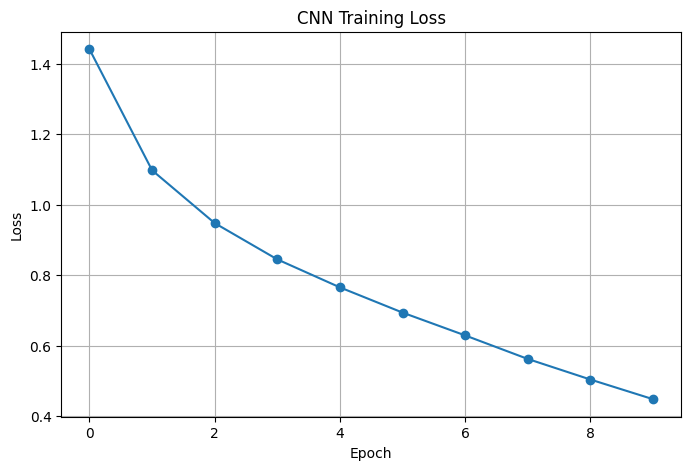

Accuracy on test data: 70.21%


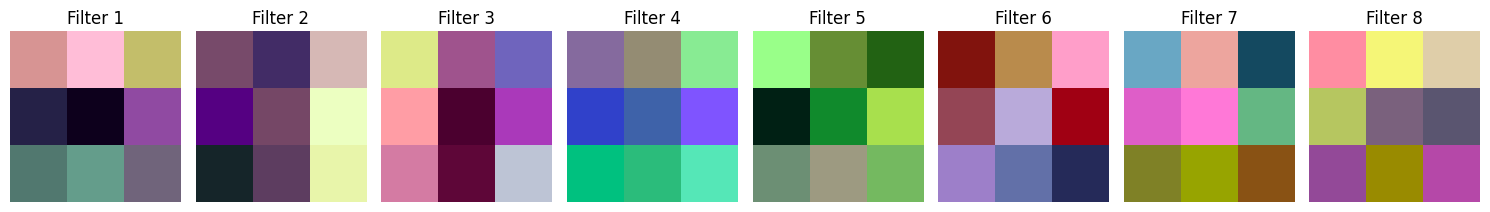

Actual Class: cat
Predicted Class: cat


In [ ]:
# ==========================================
# Exp-4: Implementation of a Convolutional Neural Network (CNN)
# ==========================================

# Step 1: Import Necessary Libraries

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt


# Step 2: Load and Preprocess CIFAR-10 Dataset

transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.5, 0.5, 0.5),
        (0.5, 0.5, 0.5)
    )
])

trainset = torchvision.datasets.CIFAR10(
    root='./data',
    train=True,
    download=True,
    transform=transform
)

testset = torchvision.datasets.CIFAR10(
    root='./data',
    train=False,
    download=True,
    transform=transform
)

trainloader = torch.utils.data.DataLoader(
    trainset,
    batch_size=64,
    shuffle=True
)

testloader = torch.utils.data.DataLoader(
    testset,
    batch_size=64,
    shuffle=False
)

classes = trainset.classes

print("Training samples:", len(trainset))
print("Testing samples:", len(testset))
print("Classes:", classes)


# Step 3: Define the CNN Architecture

class SimpleCNN(nn.Module):

    def __init__(self):
        super(SimpleCNN, self).__init__()

        self.conv1 = nn.Conv2d(
            3, 16, kernel_size=3, padding=1
        )

        self.conv2 = nn.Conv2d(
            16, 32, kernel_size=3, padding=1
        )

        self.pool = nn.MaxPool2d(2, 2)

        self.fc1 = nn.Linear(
            32 * 8 * 8,
            128
        )

        self.fc2 = nn.Linear(
            128,
            10
        )

        self.relu = nn.ReLU()

    def forward(self, x):

        # First convolution + pooling
        x = self.pool(
            self.relu(
                self.conv1(x)
            )
        )

        # Second convolution + pooling
        x = self.pool(
            self.relu(
                self.conv2(x)
            )
        )

        # Flatten
        x = x.view(
            -1,
            32 * 8 * 8
        )

        # Fully connected layers
        x = self.relu(
            self.fc1(x)
        )

        x = self.fc2(x)

        return x


# Step 4: Train the CNN

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = SimpleCNN().to(device)

loss_function = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

epochs = 10
losses = []

print("Using device:", device)

for epoch in range(epochs):

    running_loss = 0.0

    model.train()

    for images, labels in trainloader:

        images = images.to(device)
        labels = labels.to(device)

        # Forward propagation
        outputs = model(images)

        # Calculate loss
        loss = loss_function(
            outputs,
            labels
        )

        # Backpropagation
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()

    average_loss = (
        running_loss / len(trainloader)
    )

    losses.append(average_loss)

    print(
        f"Epoch {epoch + 1}/{epochs}, "
        f"Loss: {average_loss:.4f}"
    )


# Step 5: Visualize Training Loss

plt.figure(figsize=(8, 5))

plt.plot(
    losses,
    marker='o'
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("CNN Training Loss")

plt.grid(True)
plt.show()


# Step 6: Evaluate Model Performance

correct = 0
total = 0

model.eval()

with torch.no_grad():

    for images, labels in testloader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)

        _, predicted = torch.max(
            outputs,
            1
        )

        total += labels.size(0)

        correct += (
            predicted == labels
        ).sum().item()

accuracy = 100 * correct / total

print(
    f"Accuracy on test data: "
    f"{accuracy:.2f}%"
)


# Step 7: Visualize Learned Filters

def visualize_filters(layer, n_filters=8):

    filters = (
        layer.weight.data
        .clone()
        .cpu()
    )

    plt.figure(figsize=(15, 4))

    for i in range(n_filters):

        filter_image = filters[i]

        # Normalize filter values
        filter_image = (
            filter_image - filter_image.min()
        ) / (
            filter_image.max()
            - filter_image.min()
            + 1e-8
        )

        plt.subplot(1, n_filters, i + 1)

        plt.imshow(
            filter_image.permute(1, 2, 0)
        )

        plt.title(
            f"Filter {i + 1}"
        )

        plt.axis('off')

    plt.tight_layout()
    plt.show()


visualize_filters(
    model.conv1,
    n_filters=8
)


# Step 8: Predict a Sample Image

image, actual_label = testset[0]

input_image = image.unsqueeze(0).to(device)

model.eval()

with torch.no_grad():

    output = model(input_image)

    prediction = torch.argmax(
        output,
        dim=1
    ).item()

print(
    "Actual Class:",
    classes[actual_label]
)

print(
    "Predicted Class:",
    classes[prediction]
)